<a href="https://colab.research.google.com/github/aamyardra-rgb/TEXT-AND-IMAGE-PROCESSING/blob/main/spam_email_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [17]:
import string
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [18]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [19]:
import warnings
warnings.filterwarnings('ignore')

In [20]:
data = pd.read_csv('Emails.csv')
data.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


In [21]:
data.shape

(5171, 4)

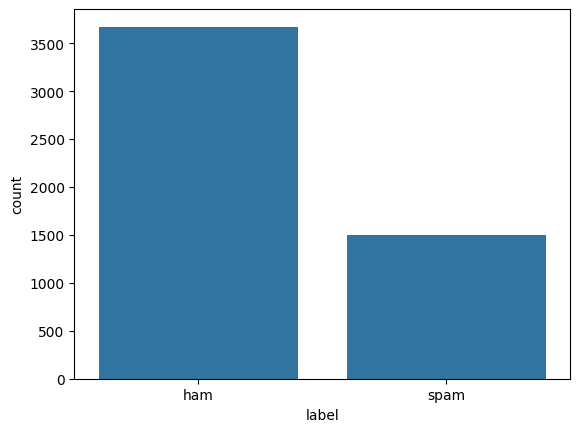

In [22]:
sns.countplot(x ='label',data = data)
plt.show()

([<matplotlib.axis.XTick at 0x77feccb51090>,
 [Text(0, 0, 'Ham (Not Spam)'), Text(1, 0, 'Spam')])

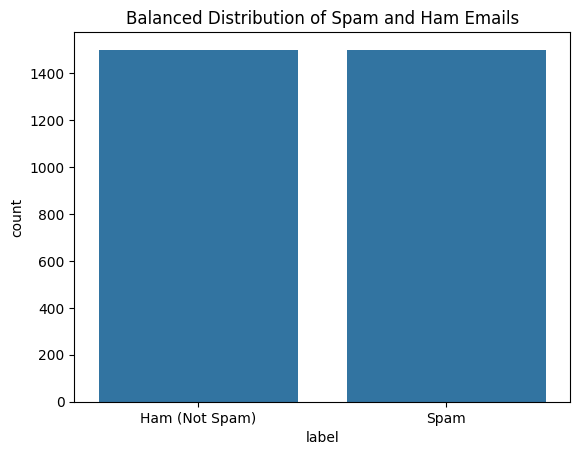

In [23]:
# imbalance in the dataset
# to balance the dataset

ham_msg = data[data['label'] == 'ham']
spam_msg = data[data['label'] == 'spam']

# Downsample ham emails to match the number of spam emails
ham_msg_balanced = ham_msg.sample(n = len(spam_msg),random_state = 42)

# combine balanced data
balanced_data = pd.concat([ham_msg_balanced,spam_msg]).reset_index(drop = True)

# visualize the balanced dataset
sns.countplot(x = 'label',data = balanced_data)
plt.title("Balanced Distribution of Spam and Ham Emails")
plt.xticks(ticks=[0,1], labels = ['Ham (Not Spam)','Spam'])


In [24]:
# clean the text
balanced_data['text'] = balanced_data['text'].str.replace('Subject','')
balanced_data.head()

,Unnamed: 0,label,text,label_num
0,3444,ham,: conoco - big cowboy\r\ndarren :\r\ni ' m not...,0
1,2982,ham,: feb 01 prod : sale to teco gas processing\r\...,0
2,2711,ham,": california energy crisis\r\ncalifornia  , s...",0
3,3116,ham,: re : nom / actual volume for april 23 rd\r\n...,0
4,1314,ham,: eastrans nomination changes effective 8 / 2 ...,0


In [25]:
punctuations_list = string.punctuation
def remove_punctuations(text):
  temp = str.maketrans('','',punctuations_list)
  return text.translate(temp)

balanced_data['text']= balanced_data['text'].apply(lambda x: remove_punctuations(x))
balanced_data.head()


,Unnamed: 0,label,text,label_num
0,3444,ham,conoco big cowboy\r\ndarren \r\ni m not sur...,0
1,2982,ham,feb 01 prod sale to teco gas processing\r\ns...,0
2,2711,ham,california energy crisis\r\ncalifornia  s p...,0
3,3116,ham,re nom actual volume for april 23 rd\r\nwe ...,0
4,1314,ham,eastrans nomination changes effective 8 2 0...,0


In [26]:
# removing stopwords
def remove_stopwords(text):
    stop_words = stopwords.words('english')

    imp_words = []

    # Storing the important words
    for word in str(text).split():
        word = word.lower()

        if word not in stop_words:
            imp_words.append(word)

    output = " ".join(imp_words)

    return output


balanced_data['text'] = balanced_data['text'].apply(lambda text: remove_stopwords(text))
balanced_data.head()

,Unnamed: 0,label,text,label_num
0,3444,ham,conoco big cowboy darren sure help know else a...,0
1,2982,ham,feb 01 prod sale teco gas processing sale deal...,0
2,2711,ham,california energy crisis california  power cr...,0
3,3116,ham,nom actual volume april 23 rd agree eileen pon...,0
4,1314,ham,eastrans nomination changes effective 8 2 00 p...,0


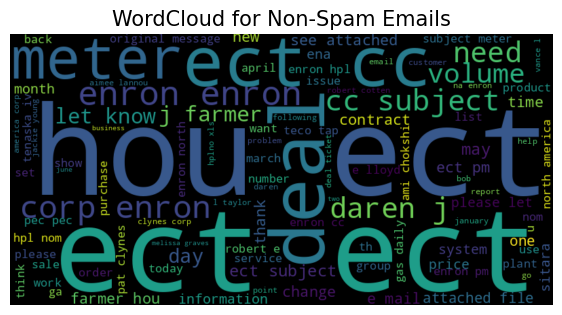

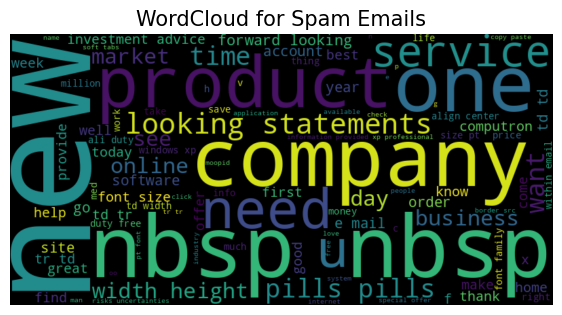

In [27]:
# visualization word cloud
# A word cloud is a text visualization tool that helps us to get insights into the most frequent words present in the corpus of data.

def plot_word_cloud(data,typ):
  email_corpus = " ".join(data['text'])
  wc = WordCloud(background_color = 'black',
                 max_words = 100,
                 width = 800,

  height = 400).generate(email_corpus)

  plt.figure(figsize=(7,7))
  plt.imshow(wc,interpolation = 'bilinear')
  plt.title(f'WordCloud for {typ} Emails',
fontsize = 15)
  plt.axis('off')
  plt.show()

plot_word_cloud(balanced_data[balanced_data['label'] == 'ham'],typ = 'Non-Spam')
plot_word_cloud(balanced_data[balanced_data['label']== 'spam'],typ = 'Spam')

In [28]:
print(balanced_data[balanced_data['label'] == 'ham'].shape)
print(balanced_data[balanced_data['label']== 'spam'].shape)

(1499, 4)
(1499, 4)


In [29]:
print(balanced_data['text'].isnull().sum())

0


In [31]:
# Tokenization and Padding
train_X,test_X,train_Y,test_Y = train_test_split(balanced_data['text'],balanced_data['label'],test_size = 0.2,random_state = 42)

tokenizer = Tokenizer()
tokenizer.fit_on_texts(train_X)

train_sequences = tokenizer.texts_to_sequences(train_X)
test_sequences = tokenizer.texts_to_sequences(test_X)

max_len = 100  # maximum sequence length
train_sequences = pad_sequences(train_sequences, maxlen = max_len, padding= 'post',truncating='post')
test_sequences = pad_sequences(test_sequences,maxlen = max_len,padding= 'post',truncating = 'post')

train_Y = (train_Y == 'spam').astype(int)
test_Y = (test_Y == 'spam').astype(int)

In [44]:
# Define the model
# Deep learning model with a sequential architechture
# Embedding layer - learn vector representation of words
# LSTM Layer - captures patterns in sequences
# Fully Connected Layer - Extract relevent features
# Output layer - Predicts whether a email is spam or not.

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(max_len,)),
    tf.keras.layers.Embedding(input_dim=len(tokenizer.word_index) + 1,output_dim=32),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(32, activation= 'relu'),
    tf.keras.layers.Dense(1, activation= 'sigmoid')
])
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(from_logits= True),
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 100, 32)        │     1,274,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,278,625 (4.88 MB)

 Trainable params: 1,278,625 (4.88 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
es = EarlyStopping(patience=3, monitor='val_accuracy', restore_best_weights=True)
lr = ReduceLROnPlateau(patience=22, monitor='val_loss', factor=0.5, verbose=0)

history = model.fit(
    train_sequences,train_Y,
    validation_data =(test_sequences, test_Y),
    epochs=20,
    batch_size=32,
    callbacks=[lr,es]
)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9028 - loss: 0.2866 - val_accuracy: 0.9250 - val_loss: 0.2795 - learning_rate: 0.0010
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.9399 - loss: 0.2132 - val_accuracy: 0.9450 - val_loss: 0.1956 - learning_rate: 0.0010
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9608 - loss: 0.1582 - val_accuracy: 0.9633 - val_loss: 0.1606 - learning_rate: 0.0010
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9679 - loss: 0.1337 - val_accuracy: 0.9667 - val_loss: 0.1325 - learning_rate: 0.0010
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.9708 - loss: 0.1151 - val_accuracy: 0.9733 - val_loss: 0.1250 - learning_rate: 0.0010
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9708 - loss: 0.1127 - val_accuracy: 0.9600 - val_loss: 0.1453 - learning_rate: 0.0010
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9683 - loss: 0.1119 - val_acc

In [51]:
test_loss, test_accuracy = model.evaluate(test_sequences, test_Y)
print('Test Loss :',test_loss)
print('Test Accuracy :',test_accuracy)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9733 - loss: 0.1250
Test Loss : 0.12504275143146515
Test Accuracy : 0.9733333587646484


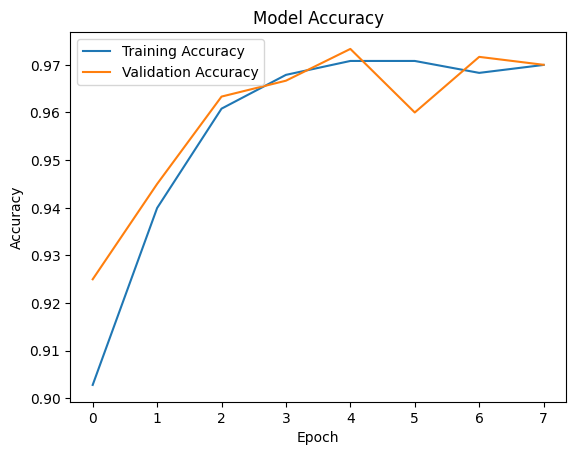

In [52]:
plt.plot(history.history['accuracy'], label = 'Training Accuracy')
plt.plot(history.history['val_accuracy'], label= 'Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()